# 📊 Sales Prediction Using Machine Learning

### CodeAlpha Data Science Internship Project

**Predicting product sales from advertising expenditure using Python and machine learning.**

---

**Objective:** Build and evaluate regression models that estimate sales using TV, radio, and newspaper advertising expenditure.

**Tools:** Python · Pandas · NumPy · Matplotlib · Seaborn · Scikit-learn

**Dataset:** Advertising.csv

**Project Domain:** Data Science | Predictive Analytics | Machine Learning

**Project workflow:** Data Understanding → Data Cleaning → Exploratory Analysis → Model Development → Evaluation → Business Insights

## Importing Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import (
    r2_score,
    mean_absolute_error,
    mean_squared_error
)
from sklearn.pipeline import Pipeline



## Data Inspecting And Cleaning 

In [2]:
sales = pd.read_csv("Advertising.csv")

In [3]:
sales.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 5 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  200 non-null    int64  
 1   TV          200 non-null    float64
 2   Radio       200 non-null    float64
 3   Newspaper   200 non-null    float64
 4   Sales       200 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 7.9 KB


In [4]:
sales.head(20)

,Unnamed: 0,TV,Radio,Newspaper,Sales
0,1,230.1,37.8,69.2,22.1
1,2,44.5,39.3,45.1,10.4
2,3,17.2,45.9,69.3,9.3
3,4,151.5,41.3,58.5,18.5
4,5,180.8,10.8,58.4,12.9
5,6,8.7,48.9,75.0,7.2
6,7,57.5,32.8,23.5,11.8
7,8,120.2,19.6,11.6,13.2
8,9,8.6,2.1,1.0,4.8
9,10,199.8,2.6,21.2,10.6


In [5]:
sales.isnull().sum()

Unnamed: 0    0
TV            0
Radio         0
Newspaper     0
Sales         0
dtype: int64

In [6]:
sales = sales.drop(columns=["Unnamed: 0"])

In [7]:
print(sales.columns)

Index(['TV', 'Radio', 'Newspaper', 'Sales'], dtype='object')


In [8]:
print("Dataset shape:", sales.shape)

Dataset shape: (200, 4)


In [9]:
display(sales.tail())

,TV,Radio,Newspaper,Sales
195,38.2,3.7,13.8,7.6
196,94.2,4.9,8.1,9.7
197,177.0,9.3,6.4,12.8
198,283.6,42.0,66.2,25.5
199,232.1,8.6,8.7,13.4


In [10]:
print("\nNumber of duplicate rows:", sales.duplicated().sum())


Number of duplicate rows: 0


In [11]:
print("\nInfinite values per column:")
print(
    pd.DataFrame(
        np.isinf(sales.select_dtypes(include="number")).sum(),
        columns=["Infinite Values"]
    )
)


Infinite values per column:
           Infinite Values
TV                       0
Radio                    0
Newspaper                0
Sales                    0


## Exploratory Data Analysis(EDA)

In [12]:
sales.describe().round(2)

,TV,Radio,Newspaper,Sales
count,200.00,200.00,200.00,200.00
mean,147.04,23.26,30.55,14.02
std,85.85,14.85,21.78,5.22
min,0.70,0.00,0.30,1.60
25%,74.38,9.98,12.75,10.38
50%,149.75,22.90,25.75,12.90
75%,218.82,36.52,45.10,17.40
max,296.40,49.60,114.00,27.00


##  Visualisations

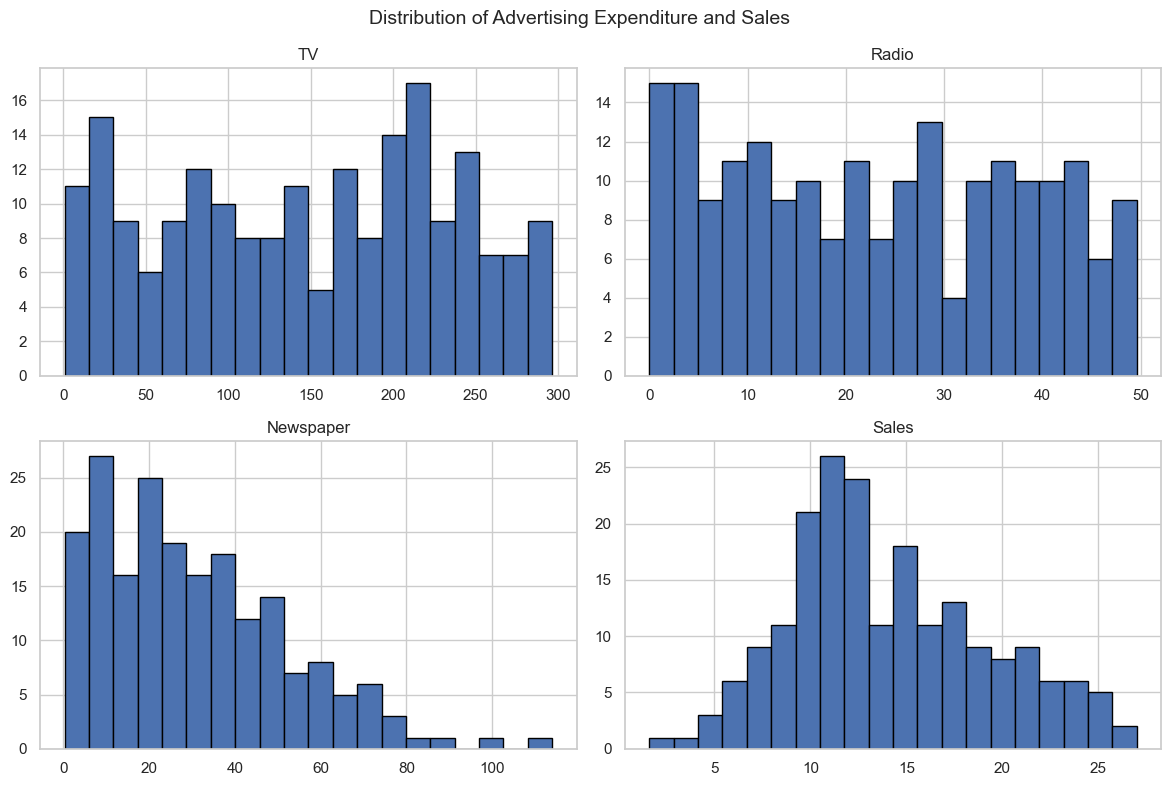

In [13]:
sns.set_theme(style="whitegrid")
features = ["TV", "Radio", "Newspaper", "Sales"]
sales[features].hist(
    figsize=(12, 8),
    bins=20,
    edgecolor="black"
)

plt.suptitle("Distribution of Advertising Expenditure and Sales", fontsize=14)
plt.tight_layout()
plt.show()


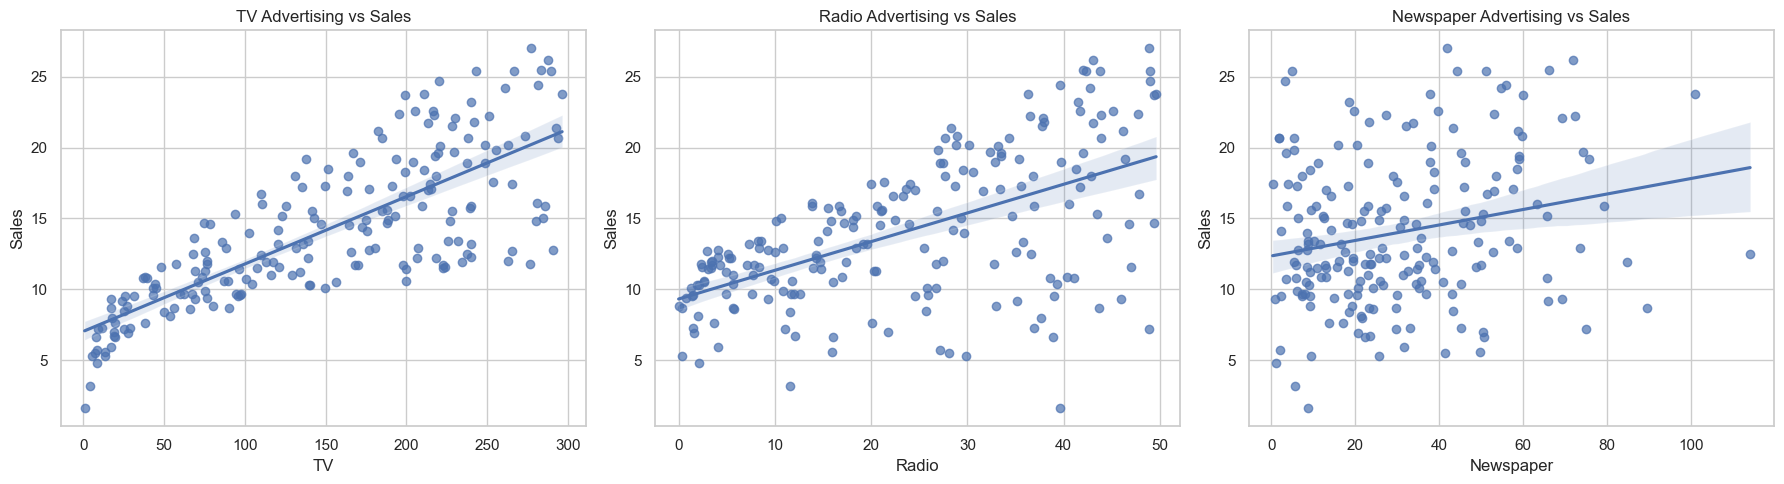

In [14]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for column, ax in zip(["TV", "Radio", "Newspaper"], axes):
    sns.regplot(
        data=sales,
        x=column,
        y="Sales",
        ax=ax,
        scatter_kws={"alpha": 0.7}
    )
    ax.set_title(f"{column} Advertising vs Sales")

plt.tight_layout()
plt.show()


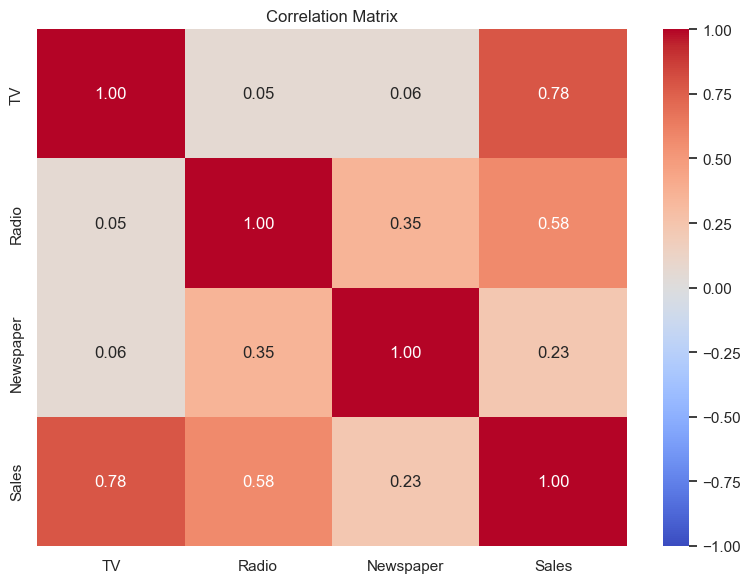

In [15]:
correlation_matrix = sales[features].corr()
plt.figure(figsize=(8, 6))
sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Matrix")
plt.tight_layout()
plt.show()


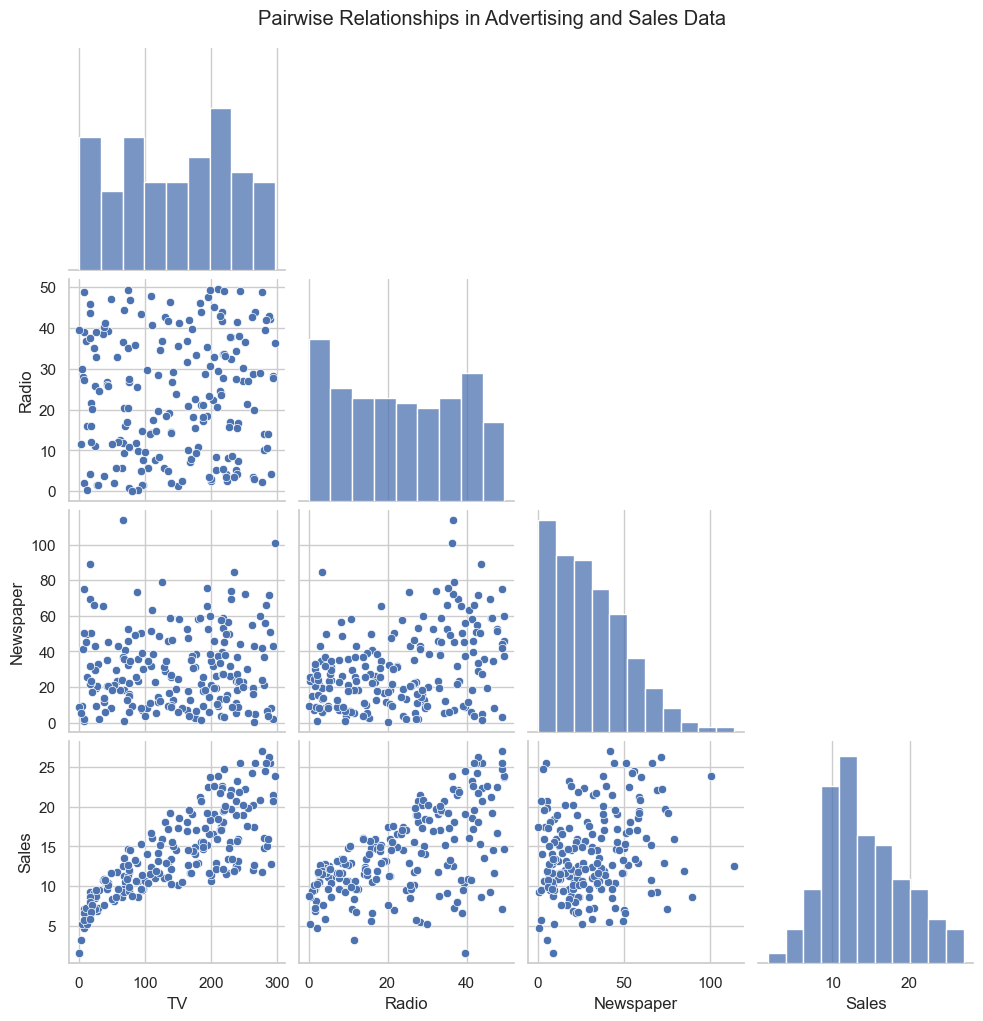

In [16]:
sns.pairplot(
    sales[["TV", "Radio", "Newspaper", "Sales"]],
    diag_kind="hist",
    corner=True
)

plt.suptitle("Pairwise Relationships in Advertising and Sales Data", y=1.02)
plt.show()


## Model Development And Evaluation 

In [38]:
models = {
    "Linear Regression": LinearRegression(),
    "Ridge Regression": Ridge(alpha=1.0),
    "Random Forest Regressor": RandomForestRegressor(
        n_estimators=100, random_state=42
    ),
    "Gradient Boosting Regressor": GradientBoostingRegressor(
        n_estimators=100, random_state=42
    )
}

In [40]:
results = []

for name, model in models.items():
    model.fit(x_train, y_train)
    predictions = model.predict(x_test)

    results.append({
        "Model": name,
        "R2 Score": r2_score(y_test, predictions),
        "MAE": mean_absolute_error(y_test, predictions),
        "RMSE": np.sqrt(mean_squared_error(y_test, predictions))
    })


In [41]:
results = pd.DataFrame(results).sort_values(
    by="RMSE", ascending=True
).reset_index(drop=True)

display(results.round(4))

,Model,R2 Score,MAE,RMSE
0,Gradient Boosting Regressor,0.9831,0.6187,0.7298
1,Random Forest Regressor,0.9813,0.6201,0.7686
2,Ridge Regression,0.8994,1.4608,1.7816
3,Linear Regression,0.8994,1.4608,1.7816


## Model Performance Comparison

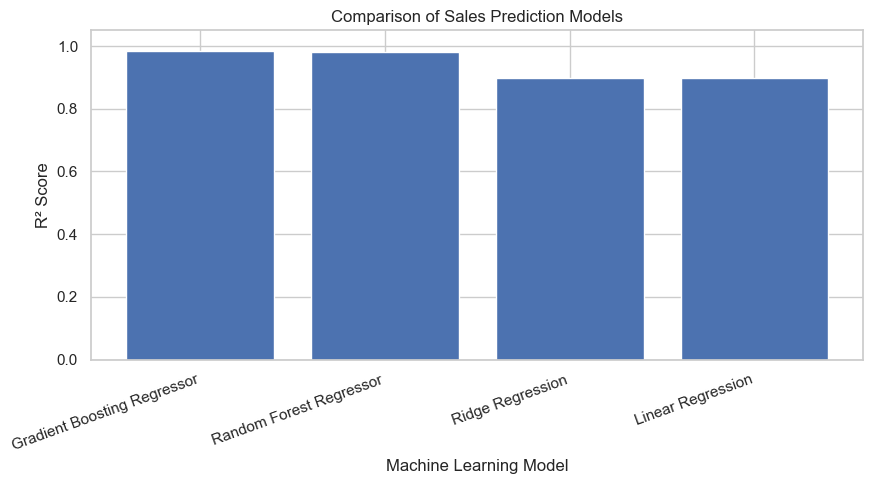

In [42]:
import matplotlib.pyplot as plt

plt.figure(figsize=(9, 5))
plt.bar(results["Model"], results["R2 Score"])

plt.title("Comparison of Sales Prediction Models")
plt.xlabel("Machine Learning Model")
plt.ylabel("R² Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

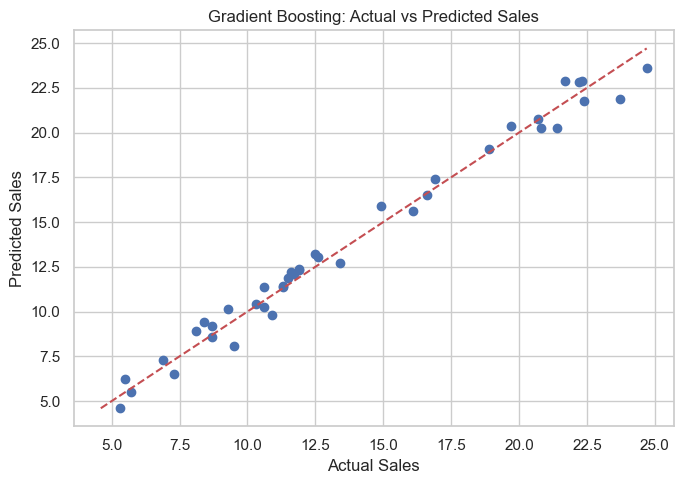

In [46]:
best_model = models["Gradient Boosting Regressor"]
predictions = best_model.predict(x_test)

plt.figure(figsize=(7, 5))
plt.scatter(y_test, predictions)

lower = min(y_test.min(), predictions.min())
upper = max(y_test.max(), predictions.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Gradient Boosting: Actual vs Predicted Sales")
plt.tight_layout()
plt.show()

In [48]:
feature_importance = pd.DataFrame({
    "Advertising Channel": x_train.columns,
    "Importance": best_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance", ascending=False
)

display(feature_importance.round(4))

,Advertising Channel,Importance
0,TV,0.6126
1,Radio,0.3809
2,Newspaper,0.0065


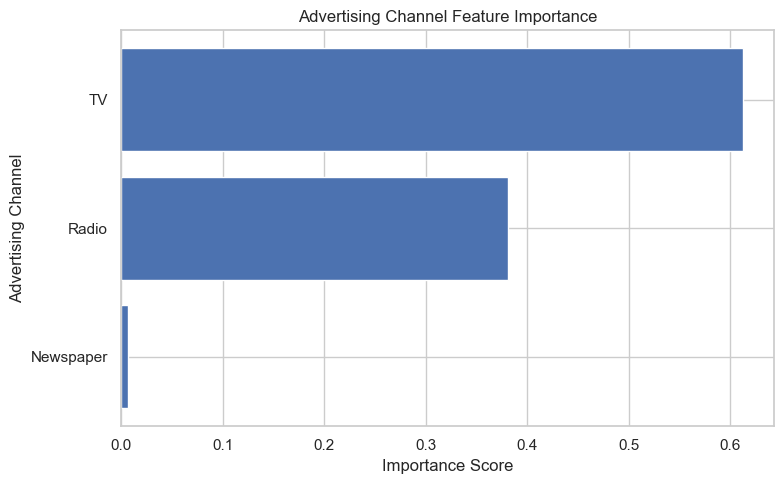

In [49]:
plt.figure(figsize=(8, 5))
plt.barh(
    feature_importance["Advertising Channel"],
    feature_importance["Importance"]
)

plt.title("Advertising Channel Feature Importance")
plt.xlabel("Importance Score")
plt.ylabel("Advertising Channel")
plt.gca().invert_yaxis()
plt.tight_layout()
plt.show()

##  Interpretation of the Sales Prediction
The trained Gradient Boosting Regressor was used to estimate sales based on a sample advertising budget consisting of TV expenditure of 150 units, radio expenditure of 25 units, and newspaper expenditure of 20 units.

In [50]:
import joblib

In [51]:
best_model_name = results.loc[
    results["RMSE"].idxmin(), "Model"
]


In [52]:
final_model = models[best_model_name]

In [53]:
joblib.dump(final_model, "sales_prediction_model.pkl")

print("Selected model:", best_model_name)
print("Model saved successfully as sales_prediction_model.pkl")

Selected model: Gradient Boosting Regressor
Model saved successfully as sales_prediction_model.pkl


In [54]:
final_model = joblib.load("sales_prediction_model.pkl")

new_advertising_data = pd.DataFrame({
    "TV": [150],
    "Radio": [25],
    "Newspaper": [20]
})

predicted_sales = final_model.predict(new_advertising_data)

print(f"Predicted Sales: {predicted_sales[0]:.2f}")

Predicted Sales: 14.69


##  Actual vs Predicted Sales and Residual Analysis

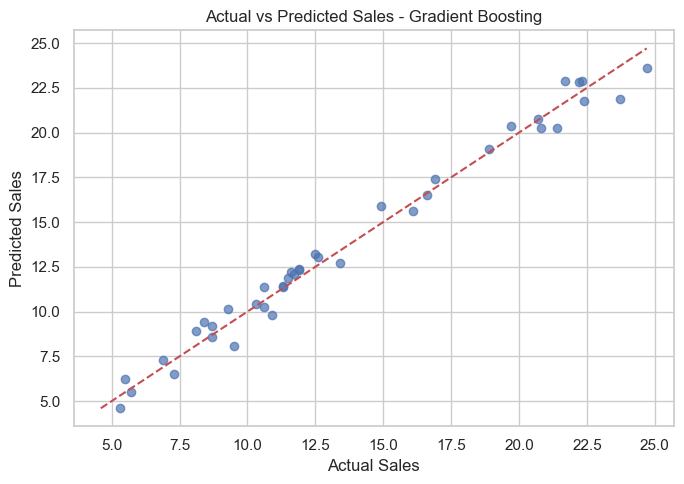

In [56]:
y_pred = final_model.predict(x_test)
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, alpha=0.7)

lower = min(y_test.min(), y_pred.min())
upper = max(y_test.max(), y_pred.max())

plt.plot([lower, upper], [lower, upper], "r--")
plt.xlabel("Actual Sales")
plt.ylabel("Predicted Sales")
plt.title("Actual vs Predicted Sales - Gradient Boosting")
plt.tight_layout()
plt.show()

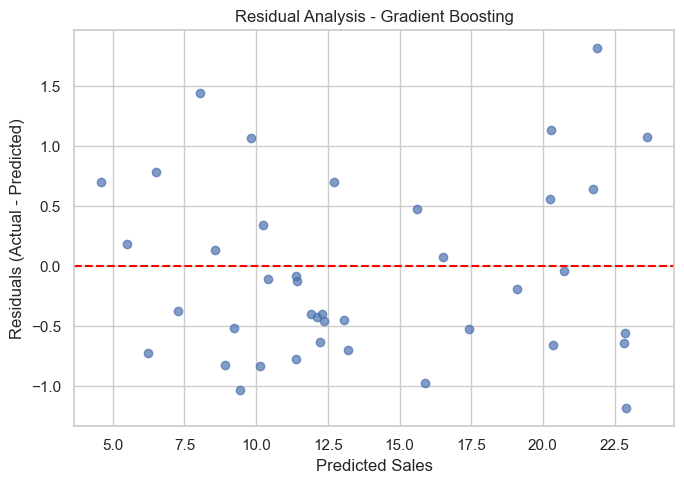

In [57]:
residuals = y_test - y_pred
plt.figure(figsize=(7, 5))
plt.scatter(y_pred, residuals, alpha=0.7)
plt.axhline(y=0, color="red", linestyle="--")

plt.xlabel("Predicted Sales")
plt.ylabel("Residuals (Actual - Predicted)")
plt.title("Residual Analysis - Gradient Boosting")
plt.tight_layout()
plt.show()

##  Business Insights And Conclusion

### Business Insight
The analysis of the advertising dataset revealed useful relationships between advertising expenditure and sales.

TV advertising has the strongest relationship with sales. The correlation matrix shows a correlation of approximately 0.78 between TV advertising and sales, indicating a strong positive relationship. The scatter plot also shows that sales generally increase as TV advertising expenditure increases. This suggests that TV advertising is an important factor to consider when planning advertising budgets.

Radio advertising also has a positive relationship with sales. Its correlation with sales is approximately 0.58. The scatter plot shows a general upward trend, although the points are more widely scattered than those for TV advertising. Radio may therefore provide additional value as part of a balanced advertising strategy.

Newspaper advertising has the weakest relationship with sales. Its correlation with sales is approximately 0.23, and its scatter plot shows a less pronounced relationship. The Gradient Boosting feature-importance chart also assigns newspaper advertising very little importance compared with TV and radio. Based on this dataset, newspaper expenditure appears less useful for predicting sales than the other two channels.

The distribution plots show that advertising expenditure varies across the three channels, while sales values are concentrated around the middle of the observed range. The pairplot further illustrates the clear positive relationship between TV expenditure and sales, the moderate positive relationship for radio, and the weaker relationship for newspaper advertising.





### Model Performance and Evaluation

Four regression models were trained and evaluated: Linear Regression, Ridge Regression, Random Forest Regressor, and Gradient Boosting Regressor.

The Gradient Boosting Regressor achieved the best performance on the test dataset, with an R² score of 0.9831, an MAE of 0.6187, and an RMSE of 0.7298. The Random Forest Regressor also performed well, achieving an R² score of 0.9813 and an RMSE of 0.7686.

Linear Regression and Ridge Regression both achieved an R² score of 0.8994 and an RMSE of 1.7816. Although these models provided reasonable baseline predictions, the ensemble models achieved lower prediction errors on the test data.

The actual-versus-predicted plot for Gradient Boosting shows that most points lie close to the reference line, indicating that the model's predictions are generally close to the observed sales values. The residual plot shows errors on both sides of the zero line, with some predictions having larger errors than others. These results suggest good predictive performance, although the model is not perfectly accurate.

Based on the evaluated test-set results, Gradient Boosting Regressor was selected as the final model for this project.


### Business Recommendations

Based on the findings, businesses could consider the following recommendations:

Prioritize evaluating TV advertising: TV expenditure showed the strongest relationship with sales in this dataset. Businesses should assess its potential when allocating advertising budgets.

Consider radio as a complementary channel: Radio also showed a positive relationship with sales and may be useful alongside TV advertising.

Review newspaper advertising performance: Because newspaper expenditure had a weaker relationship with sales, businesses should evaluate its return on investment before increasing or reducing spending.

Use predictions to support planning: The selected Gradient Boosting model can provide estimated sales for proposed advertising budgets. These estimates should complement, rather than replace, business judgment and actual campaign-performance data.

Monitor performance over time: Businesses should compare predicted sales with actual outcomes as new data becomes available and retrain or reassess the model when necessary.

These recommendations should be treated as guidance rather than proof that changing expenditure on a particular channel will directly cause sales to change. The analysis identifies relationships in historical data; it does not establish causation or directly measure the profitability of each channel.


### Conclusion

This project examined how TV, radio, and newspaper advertising expenditure relates to sales and evaluated four machine learning models for sales prediction. The exploratory analysis showed that TV advertising had the strongest correlation with sales, followed by radio, while newspaper advertising had a weaker relationship.

Among the four models evaluated, Gradient Boosting Regressor achieved the strongest test-set performance, with an R² score of 0.9831 and an RMSE of 0.7298. The actual-versus-predicted plot supported this result by showing predictions generally close to the observed sales values, while the residual plot revealed that some prediction errors remained.

Overall, the project demonstrates how exploratory data analysis and machine learning can help businesses understand advertising-related sales patterns and estimate sales from advertising expenditure. The results provide a useful basis for further investigation into advertising-budget decisions, while recognizing that the findings are limited to the available dataset and evaluation procedure.